In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ayushish12/positionsalaries-data/position-salaries data.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/kaggle/input/datasets/ayushish12/positionsalaries-data/position-salaries data.csv')

df.head()


,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [4]:
X = df['Level'].values.reshape(-1, 1)
y = df['Salary'].values.reshape(-1, 1)

In [5]:
X_mean = np.mean(X)
X_std = np.std(X)

X_scaled = (X - X_mean) / X_std

X_poly = np.hstack((
    np.ones((len(X), 1)),
    X_scaled,
    X_scaled**2,
    X_scaled**3,
    X_scaled**4
))

y_scaled = y / 100000

In [6]:
n = len(X)
m_features = X_poly.shape[1]

weights = np.zeros((m_features, 1))

learning_rate = 0.01
epochs = 2000

beta = 0.9

velocity = np.zeros_like(weights)

loss_history = []

In [7]:
for epoch in range(epochs):

    # Shuffle data
    indices = np.random.permutation(n)

    for i in indices:

        # Select one sample
        x_i = X_poly[i:i+1]
        y_i = y_scaled[i:i+1]

        # Prediction
        y_pred = x_i @ weights

        # Error
        error = y_pred - y_i

        # Gradient
        dw = 2 * (x_i.T @ error)

        # Momentum
        velocity = beta * velocity + (1 - beta) * dw

        # Update weights
        weights -= learning_rate * velocity

    # Calculate Loss after each epoch
    y_pred_all = X_poly @ weights
    loss = np.mean((y_pred_all - y_scaled) ** 2)

    loss_history.append(loss)

print("Final Loss:", loss_history[-1])
print("Weights:")
print(weights)

Final Loss: 0.021188362612743657
Weights:
[[1.32154304]
 [0.580924  ]
 [0.0963392 ]
 [0.98626023]
 [0.6077459 ]]


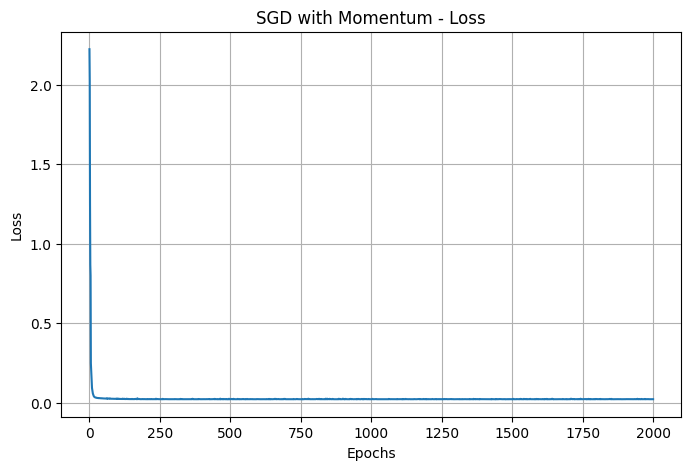

In [8]:
plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('SGD with Momentum - Loss')

plt.grid()
plt.show()

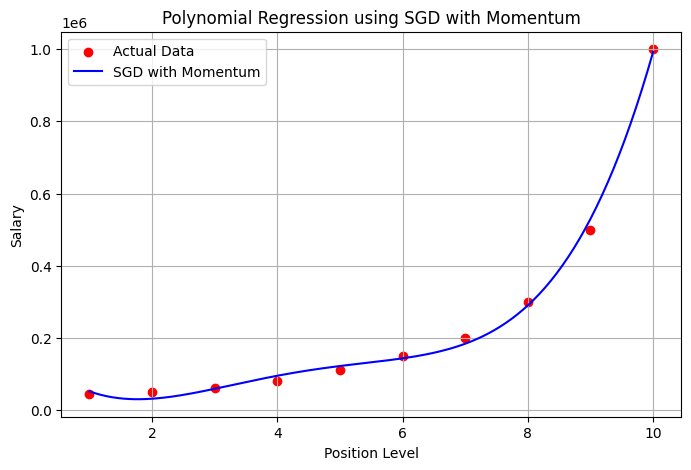

In [9]:
X_curve = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

X_curve_scaled = (X_curve - X_mean) / X_std

X_curve_poly = np.hstack((
    np.ones((len(X_curve), 1)),
    X_curve_scaled,
    X_curve_scaled**2,
    X_curve_scaled**3,
    X_curve_scaled**4
))

y_curve = (X_curve_poly @ weights) * 100000

plt.figure(figsize=(8,5))

plt.scatter(X, y, color='red', label='Actual Data')

plt.plot(X_curve, y_curve, color='blue', label='SGD with Momentum')

plt.xlabel('Position Level')
plt.ylabel('Salary')
plt.title('Polynomial Regression using SGD with Momentum')

plt.legend()
plt.grid()
plt.show()